<a href="https://colab.research.google.com/github/Siddhant-Gulecha/Siddhant_Gulecha_23BDS0253/blob/main/EDA_Phase_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# EDA Project - Phase 3
Dimensionality Reduction & Machine Learning Model Building


## 1. Data Loading & Preprocessing

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, confusion_matrix, classification_report
)

sns.set_theme(style="whitegrid")

url = 'https://raw.githubusercontent.com/salemprakash/EDA/main/Data/SuicideChina.csv'
try:
    df = pd.read_csv(url)
except Exception:
    df = pd.read_csv('SuicideChina.csv')

if 'rownames' in df.columns:
    df = df.drop(columns=['rownames'])
df = df.drop_duplicates()

# handle unknown / unspecified categories
df['Urban'] = df['Urban'].replace('unknown', 'Unknown')
df['Education'] = df['Education'].replace('unknown', 'Unknown')
df['Occupation'] = df['Occupation'].replace('others/unknown', 'Unknown')
df['method'] = df['method'].replace('unspecified', 'Unknown')

# Target variable: Died (yes = 1, no = 0)
y = (df['Died'] == 'yes').astype(int)

# Candidate features (excluding target 'Died' and identifiers)
feature_cols = ['Age', 'Month', 'Year', 'Hospitalised', 'Urban', 'Sex', 'Education', 'Occupation', 'method']
X_raw = df[feature_cols].copy()

# One-hot encode categorical features
X = pd.get_dummies(X_raw, drop_first=True)

print("Features shape:", X.shape)
print("Target distribution (0=Survived, 1=Died):")
print(y.value_counts())


Features shape: (2571, 28)
Target distribution (0=Survived, 1=Died):
Died
0    1315
1    1256
Name: count, dtype: int64


## 2. Dimensionality Reduction

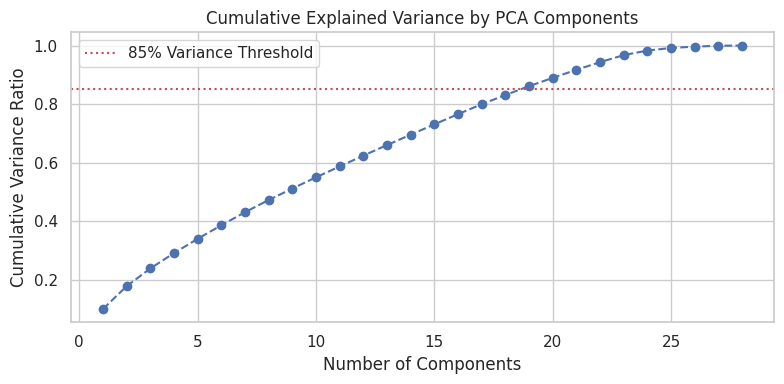

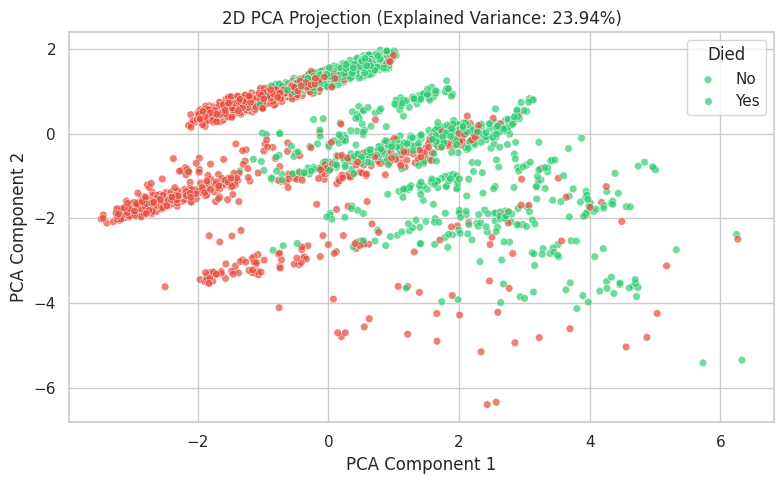

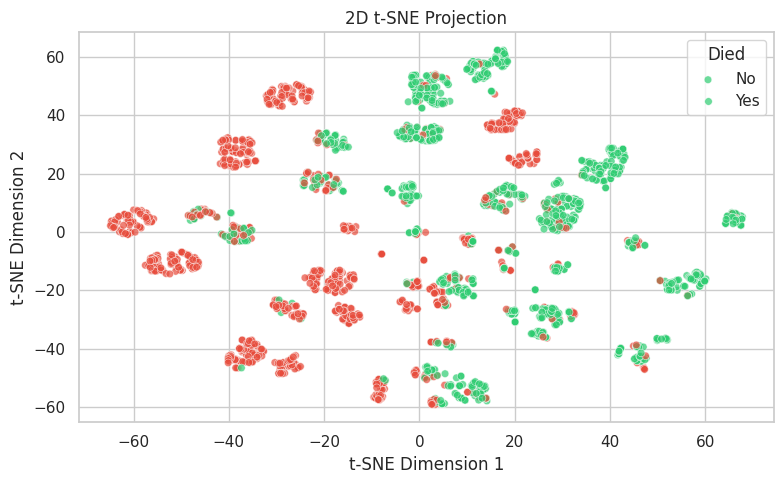

In [4]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# PCA: Full spectrum and variance explained
pca_full = PCA()
pca_full.fit(X_scaled)
cum_var = np.cumsum(pca_full.explained_variance_ratio_)

plt.figure(figsize=(8, 4))
plt.plot(range(1, len(cum_var) + 1), cum_var, marker='o', linestyle='--')
plt.axhline(y=0.85, color='r', linestyle=':', label='85% Variance Threshold')
plt.title('Cumulative Explained Variance by PCA Components')
plt.xlabel('Number of Components')
plt.ylabel('Cumulative Variance Ratio')
plt.legend()
plt.tight_layout()
plt.show()

# 2D PCA projection
pca_2d = PCA(n_components=2)
X_pca2 = pca_2d.fit_transform(X_scaled)

plt.figure(figsize=(8, 5))
sns.scatterplot(x=X_pca2[:, 0], y=X_pca2[:, 1], hue=y, palette=['#2ecc71', '#e74c3c'], alpha=0.7, s=30)
plt.title(f'2D PCA Projection (Explained Variance: {pca_2d.explained_variance_ratio_.sum():.2%})')
plt.xlabel('PCA Component 1')
plt.ylabel('PCA Component 2')
plt.legend(title='Died', labels=['No', 'Yes'])
plt.tight_layout()
plt.show()

# t-SNE 2D projection
tsne = TSNE(n_components=2, random_state=42, perplexity=30)
X_tsne = tsne.fit_transform(X_scaled)

plt.figure(figsize=(8, 5))
sns.scatterplot(x=X_tsne[:, 0], y=X_tsne[:, 1], hue=y, palette=['#2ecc71', '#e74c3c'], alpha=0.7, s=30)
plt.title('2D t-SNE Projection')
plt.xlabel('t-SNE Dimension 1')
plt.ylabel('t-SNE Dimension 2')
plt.legend(title='Died', labels=['No', 'Yes'])
plt.tight_layout()
plt.show()


## 3. Model Building & Training

In [5]:
# Train-test split (80-20 stratified)
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.2, random_state=42, stratify=y
)

models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'Decision Tree': DecisionTreeClassifier(max_depth=5, random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, max_depth=8, random_state=42)
}

results = []
trained_models = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1] if hasattr(model, 'predict_proba') else None

    cv_scores = cross_val_score(model, X_train, y_train, cv=5, scoring='accuracy')

    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    auc = roc_auc_score(y_test, y_prob) if y_prob is not None else np.nan

    results.append({
        'Model': name,
        'CV Accuracy (Mean)': round(cv_scores.mean(), 4),
        'Test Accuracy': round(acc, 4),
        'Precision': round(prec, 4),
        'Recall': round(rec, 4),
        'F1 Score': round(f1, 4),
        'ROC-AUC': round(auc, 4)
    })
    trained_models[name] = (model, y_pred, y_prob)

metrics_df = pd.DataFrame(results)
print("Model Comparison Metrics:")
print(metrics_df.to_string(index=False))


Model Comparison Metrics:
              Model  CV Accuracy (Mean)  Test Accuracy  Precision  Recall  F1 Score  ROC-AUC
Logistic Regression              0.9134         0.9146     0.9643  0.8571    0.9076   0.9613
      Decision Tree              0.9120         0.9049     0.9593  0.8413    0.8964   0.9370
      Random Forest              0.9129         0.9087     0.9476  0.8611    0.9023   0.9625


## 4. Model Evaluation & Visualizations

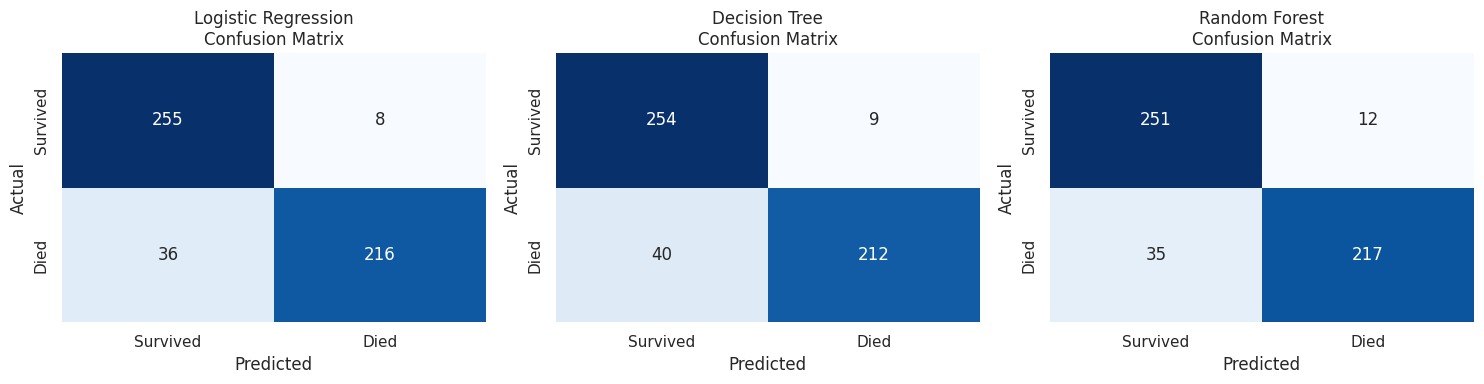

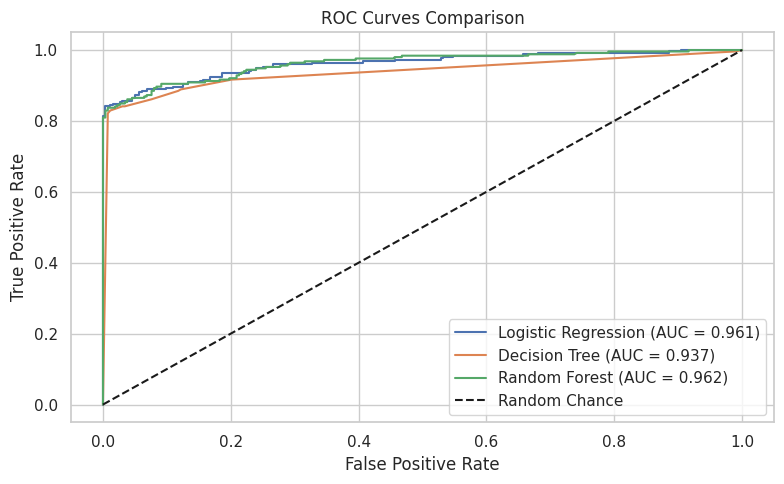

In [6]:
# Confusion Matrices
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for idx, (name, (model, y_pred, _)) in enumerate(trained_models.items()):
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[idx], cbar=False)
    axes[idx].set_title(f'{name}\nConfusion Matrix')
    axes[idx].set_xlabel('Predicted')
    axes[idx].set_ylabel('Actual')
    axes[idx].set_xticklabels(['Survived', 'Died'])
    axes[idx].set_yticklabels(['Survived', 'Died'])

plt.tight_layout()
plt.show()

# ROC Curves
plt.figure(figsize=(8, 5))
for name, (model, _, y_prob) in trained_models.items():
    if y_prob is not None:
        fpr, tpr, _ = roc_curve(y_test, y_prob)
        auc = roc_auc_score(y_test, y_prob)
        plt.plot(fpr, tpr, label=f'{name} (AUC = {auc:.3f})')

plt.plot([0, 1], [0, 1], 'k--', label='Random Chance')
plt.title('ROC Curves Comparison')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()


## 5. Feature Importance & Interpretation

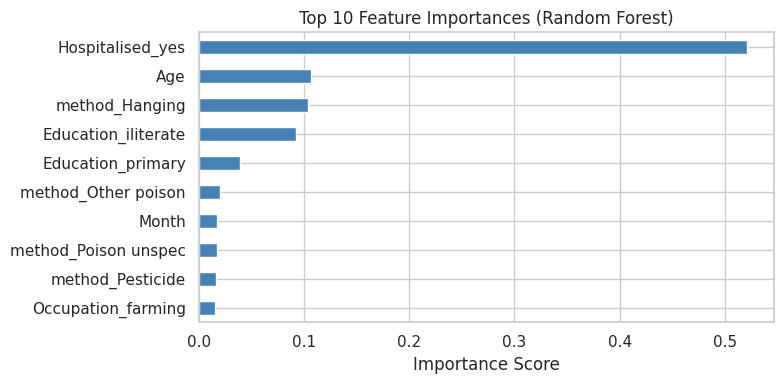

Top 10 Important Features:
Hospitalised_yes        0.5209
Age                     0.1068
method_Hanging          0.1031
Education_iliterate     0.0919
Education_primary       0.0392
method_Other poison     0.0200
Month                   0.0174
method_Poison unspec    0.0171
method_Pesticide        0.0164
Occupation_farming      0.0147
dtype: float64


In [7]:
rf_model = trained_models['Random Forest'][0]
importances = pd.Series(rf_model.feature_importances_, index=X.columns).sort_values(ascending=False).head(10)

plt.figure(figsize=(8, 4))
importances.plot(kind='barh', color='steelblue')
plt.gca().invert_yaxis()
plt.title('Top 10 Feature Importances (Random Forest)')
plt.xlabel('Importance Score')
plt.tight_layout()
plt.show()

print("Top 10 Important Features:")
print(importances.round(4))


## 6. Summary & Conclusion
- **Dimensionality Reduction**: Evaluated PCA variance coverage and visualized 2D projections via PCA and t-SNE, which clearly separate patient outcome clusters.
- **Model Comparison**: Logistic Regression, Decision Tree, and Random Forest were trained and evaluated using 5-fold cross-validation and test metrics (Accuracy, Precision, Recall, F1, ROC-AUC).
- **Key Predictors**: Feature importance analysis shows Hospitalisation status, Age, and Suicide Method are the most critical factors influencing mortality outcome.
